# Overfitting check: mentors' 6-month / 3-month split + walk-forward validation 
Tomorrow the model is scored on **3 unseen months**. Leave-one-test-out (LOO) error is *interpolation* — the left-out test has neighbours on both sides in time — so it is optimistic for anything with a time trend (the water model).

Here we simulate the real situation honestly:
* well-test labels **only before a cut-off** are used for fitting (J, offset, water trend, GOR, model choice);
* the JT coefficient `eta` is also fitted only on pre-cut-off data;
* high-frequency data after the cut-off *is* used (tomorrow you will have it), exactly like the real case;
* error is measured on the well tests **after** the cut-off.

The mentors' hint is cut-off = 2025-07-01 (train Jan–Jun, validate Jul–Sep). We also repeat it for 4 cut-offs (**walk-forward / rolling-origin**), which gives ~130 validation points instead of 29 and makes model choice far less dependent on luck.

Run after `Phase1_VFM.ipynb`.

In [1]:
import pandas as pd, numpy as np, os
import matplotlib.pyplot as plt
%matplotlib inline
DATA_DIR = '../data/'; WORK_DIR = '../work/'; OUT_DIR = '../results/'
T0 = pd.Timestamp('2025-01-01')
CUTOFFS = ['2025-05-01', '2025-06-01', '2025-07-01', '2025-08-01']   # 2025-07-01 = mentors' split
c = pd.read_pickle(WORK_DIR + 'clean.pkl')
pvt = pd.read_csv(DATA_DIR + 'reservoir_pvt.csv').set_index('well_name')
cp = pd.read_csv(DATA_DIR + 'well_completion.csv').set_index('well_name')
ch = pd.read_csv(WORK_DIR + 'choke_events_used.csv', parse_dates=['timestamp'])
wt = pd.read_csv(DATA_DIR + 'well_tests.csv', parse_dates=['test_start', 'test_end'])
for col in ['water_rate_stbd','gas_rate_mscfd','total_gas_rate_mscfd','gas_lift_rate_mscfd','oil_rate_stbd']: wt[col] = wt[col].abs()
m6 = wt.well_name == 'GL-06'; wt.loc[m6, 'gas_rate_mscfd'] /= 28.3168

### Same feature pipeline as notebooks 02–03, parametrised by the cut-off

In [2]:
def local_linear(x, y, xq, h=10.0, iters=2):
    w_r = np.ones_like(y); out = None
    for it in range(iters):
        out = np.empty_like(xq, dtype=float)
        for j, x0 in enumerate(xq):
            u = np.abs(x - x0) / h; k = np.where(u < 1, (1 - u**3)**3, 0) * w_r
            if k.sum() < 1e-6: out[j] = np.nan; continue
            X = np.c_[np.ones_like(x), x - x0]
            b = np.linalg.lstsq(X * np.sqrt(k)[:, None], y * np.sqrt(k), rcond=None)[0]; out[j] = b[0]
        r = y - np.interp(x, xq, out); s = np.median(np.abs(r)) * 6 + 1e-9
        u = np.clip(r / s, -1, 1); w_r = (1 - u**2)**2
    return out

def stable_mask(idx, ev, tests=None):
    ok = pd.Series(True, index=idx)
    for _, e in ev.iterrows():
        ok[(idx > e.timestamp - pd.Timedelta('1h')) & (idx < e.timestamp + pd.Timedelta('10h'))] = False
    for _, e in ev[ev.choke_opening_pct == 0].iterrows():
        later = ev[ev.timestamp > e.timestamp]; rs = later.timestamp.min() if len(later) else idx[-1]
        ok[(idx > e.timestamp - pd.Timedelta('1h')) & (idx < rs + pd.Timedelta('36h'))] = False
    if tests is not None:
        for _, r in tests.iterrows():
            ok[(idx >= r.test_start - pd.Timedelta('1h')) & (idx < r.test_start + pd.Timedelta('2h'))] = False
            ok[(idx >= r.test_end - pd.Timedelta('1h')) & (idx < r.test_end + pd.Timedelta('8h'))] = False
    return ok

def build_features(cut):
    tr_tests = wt[wt.test_end < cut]; minute = {}; etas = {}
    for w, g in c.groupby('well_name'):
        ev = ch[ch.well_name == w]; Tres = pvt.loc[w, 'reservoir_temperature_degf']
        gi = g.set_index('timestamp')
        h = gi[['dh_pressure_psia', 'dh_temperature_degf']].resample('1h').mean()
        # eta from pre-cut-off data only
        hh = h[(h.index < cut) & stable_mask(h.index, ev)].dropna()
        t = (hh.index - T0).total_seconds().values / 86400; X = np.c_[np.ones_like(t), t, t**2]; best = None
        for e_ in np.arange(0.0020, 0.0080, 0.00002):
            pr = hh.dh_pressure_psia.values + (hh.dh_temperature_degf.values - Tres) / e_
            s = np.median(np.abs(pr - X @ np.linalg.lstsq(X, pr, rcond=None)[0]))
            if best is None or s < best[1]: best = (e_, s)
        eta = etas[w] = best[0]
        ok = stable_mask(h.index, ev, tr_tests[tr_tests.well_name == w])
        prT = h.dh_pressure_psia + (h.dh_temperature_degf - Tres) / eta
        d = prT.where(ok).resample('1D').agg(['median', 'count']); d = d[d['count'] >= 6]
        xd = ((d.index - T0).total_seconds() / 86400 + 0.5).values
        ndays = (g.timestamp.max().normalize() - g.timestamp.min().normalize()).days + 1
        xq = (g.timestamp.min().normalize() - T0).days + np.arange(ndays) + 0.5
        prs = local_linear(xd, d['median'].values, xq)
        tday = ((g.timestamp - T0).dt.total_seconds() / 86400).values
        D = np.where(g.choke_pct.values > 0, np.clip(np.interp(tday, xq, prs) - g.dh_pressure_psia.values, 0, None), 0.0)
        minute[w] = pd.DataFrame({'timestamp': g.timestamp.values, 'D': D})
    rows = []
    for _, r in wt.iterrows():
        mm = minute[r.well_name]; s = mm[(mm.timestamp >= r.test_start) & (mm.timestamp < r.test_end)]
        rows.append(dict(D=s.D.mean(), td=((r.test_start + (r.test_end - r.test_start) / 2) - T0).total_seconds() / 86400))
    F = pd.concat([wt.reset_index(drop=True), pd.DataFrame(rows)], axis=1); F['train'] = F.test_end < cut
    return F, etas

FEATS = {}
for cut in CUTOFFS:
    FEATS[cut], etas = build_features(pd.Timestamp(cut))
    print(cut, 'train tests:', FEATS[cut].train.sum(), ' validation tests:', (~FEATS[cut].train).sum())

2025-05-01 train tests: 38  validation tests: 47


2025-06-01 train tests: 48  validation tests: 37


2025-07-01 train tests: 56  validation tests: 29


2025-08-01 train tests: 67  validation tests: 18


### Models compared (all fitted on pre-cut-off tests only)

In [3]:
def fit_oil(D, q, off):
    if off:
        W = 1 / q; b = np.linalg.lstsq(np.c_[D, np.ones_like(D)] * W[:, None], q * W, rcond=None)[0]; return b[0], b[1] / b[0]
    return np.sum(D / q) / np.sum(D**2 / q**2), 0.0

def team_offset_rule(D, q):
    n = len(D); e = {}
    for off in [False, True]:
        err = []
        for i in range(n):
            m = np.arange(n) != i; J, cc = fit_oil(D[m], q[m], off); err.append(abs(J * (D[i] + cc) / q[i] - 1))
        e[off] = np.mean(err)
    return e[True] < 0.75 * e[False]

rows = []
for cut, F in FEATS.items():
    tc = (pd.Timestamp(cut) - T0).days
    for w, g in F.groupby('well_name'):
        tr = g[g.train]; va = g[~g.train]
        if len(va) == 0: continue
        D, t, qo, qw = tr.D.values, tr.td.values, tr.oil_rate_stbd.values, tr.water_rate_stbd.values
        off = team_offset_rule(D, qo); J, cc = fit_oil(D, qo, off)
        Dv, tv = va.D.values, va.td.values
        oil = {'team (J, offset by LOO rule)': J * (Dv + cc),
               'J, never offset': fit_oil(D, qo, False)[0] * Dv,
               'J + offset, all wells': (lambda p: p[0] * (Dv + p[1]))(fit_oil(D, qo, True)),
               'J linear in time': (lambda b: (b[0] + b[1] * (tv - tc)) * Dv)(np.linalg.lstsq(np.c_[D, D * (t - tc)] / qo[:, None], np.ones_like(qo), rcond=None)[0])}
        qo_hat = oil['team (J, offset by LOO rule)']
        x = D + cc; xv = Dv + cc
        b_exp = np.linalg.lstsq(np.c_[np.ones_like(t), t], np.log(qw / x), rcond=None)[0]
        w_team = np.exp(b_exp[0] + b_exp[1] * tv) * xv
        w_wor = np.polyval(np.polyfit(t, qw / qo, 1), tv) * qo_hat
        W_ = 1 / qw; bl = np.linalg.lstsq(np.c_[x, x * t] * W_[:, None], qw * W_, rcond=None)[0]
        water = {'team: Jw = exp(a+bt)': w_team, 'WOR linear in t x oil': w_wor,
                 'ENSEMBLE: mean of both (new)': 0.5 * (w_team + w_wor),
                 'Jw linear in t': (bl[0] + bl[1] * tv) * xv,
                 'Jw constant (no trend)': (np.sum(x / qw) / np.sum(x**2 / qw**2)) * xv}
        Rs = cp.loc[w, 'solution_gor_at_pb_scf_stb'] / 1000; gt = tr.gas_rate_mscfd.sum() / qo.sum()
        gas = {'team: GOR = Rs': Rs * qo_hat, 'GOR from train tests': gt * qo_hat, 'blend': 0.5 * (Rs + gt) * qo_hat}
        for stream, dct, y in [('oil', oil, va.oil_rate_stbd.values), ('water', water, va.water_rate_stbd.values), ('gas', gas, va.gas_rate_mscfd.values)]:
            for name, pr in dct.items():
                for i in range(len(y)):
                    rows.append(dict(cutoff=cut, well=w, stream=stream, model=name, horizon_days=tv[i] - tc, ape=abs(pr[i] / y[i] - 1) * 100))
E = pd.DataFrame(rows)
tab = E.pivot_table(index=['stream', 'model'], columns='cutoff', values='ape', aggfunc='mean')
tab['ALL cut-offs'] = E.groupby(['stream', 'model']).ape.mean()
tab.round(2)

cutoff                               2025-05-01  2025-06-01  2025-07-01  \
stream model                                                              
gas    GOR from train tests                5.93        5.76        5.75   
       blend                               5.62        5.92        5.52   
       team: GOR = Rs                      5.71        6.27        5.75   
oil    J + offset, all wells               3.92        2.95        3.36   
       J linear in time                    8.78        8.07        5.85   
       J, never offset                     2.26        2.15        2.25   
       team (J, offset by LOO rule)        1.90        2.01        2.10   
water  ENSEMBLE: mean of both (new)        6.30        5.48        5.44   
       Jw constant (no trend)             15.72       15.83       16.22   
       Jw linear in t                      6.13        5.72        5.47   
       WOR linear in t x oil               7.43        5.77        5.37   
       team: Jw = exp(a+bt)                6.57        5.93        5.80   

cutoff                               2025-08-01  ALL cut-offs  
stream model                                                   
gas    GOR from train tests                5.40          5.77  
       blend                               5.64          5.69  
       team: GOR = Rs                      5.95          5.91  
oil    J + offset, all wells               2.53          3.33  
       J linear in time                    4.94          7.40  
       J, never offset                     2.53          2.27  
       team (J, offset by LOO rule)        2.54          2.06  
water  ENSEMBLE: mean of both (new)        5.41          5.76  
       Jw constant (no trend)             16.37         15.95  
       Jw linear in t                      5.58          5.79  
       WOR linear in t x oil               5.35          6.22  
       team: Jw = exp(a+bt)                5.51          6.07

### Mentors' split only (train Jan–Jun → validate Jul–Sep), per well

In [4]:
m = E[(E.cutoff == '2025-07-01') & E.model.isin(['team (J, offset by LOO rule)', 'team: Jw = exp(a+bt)', 'ENSEMBLE: mean of both (new)', 'team: GOR = Rs'])]
m.pivot_table(index='well', columns='model', values='ape', aggfunc='mean').round(2)

model,ENSEMBLE: mean of both (new),"team (J, offset by LOO rule)",team: GOR = Rs,team: Jw = exp(a+bt)
well,,,,
GL-01,10.99,1.54,3.09,8.20
GL-02,9.31,1.93,1.85,10.37
GL-03,3.76,2.72,4.34,4.68
GL-04,7.88,0.24,7.46,8.56
GL-05,5.57,3.16,10.13,5.45
GL-06,3.13,1.81,14.08,2.85
GL-07,2.50,1.22,2.88,3.58
GL-08,3.54,4.04,1.37,4.24
GL-09,3.80,2.80,7.28,4.14


### In-sample LOO vs. honest out-of-time error, and error growth with forecast horizon

,"LOO MAPE % (in-sample, notebook 03)",walk-forward MAPE % (out-of-time),optimism (pp)
oil,1.95,2.06,0.12
water,4.02,6.07,2.06
gas,5.54,5.91,0.37


model,ENSEMBLE: mean of both (new),"team (J, offset by LOO rule)",team: GOR = Rs,team: Jw = exp(a+bt)
horizon,,,,
0-1 mo,4.58,1.63,6.44,4.49
1-2 mo,5.50,2.18,6.43,5.50
2-3 mo,5.58,2.18,5.59,6.18
3-4 mo,7.38,2.21,5.27,8.32


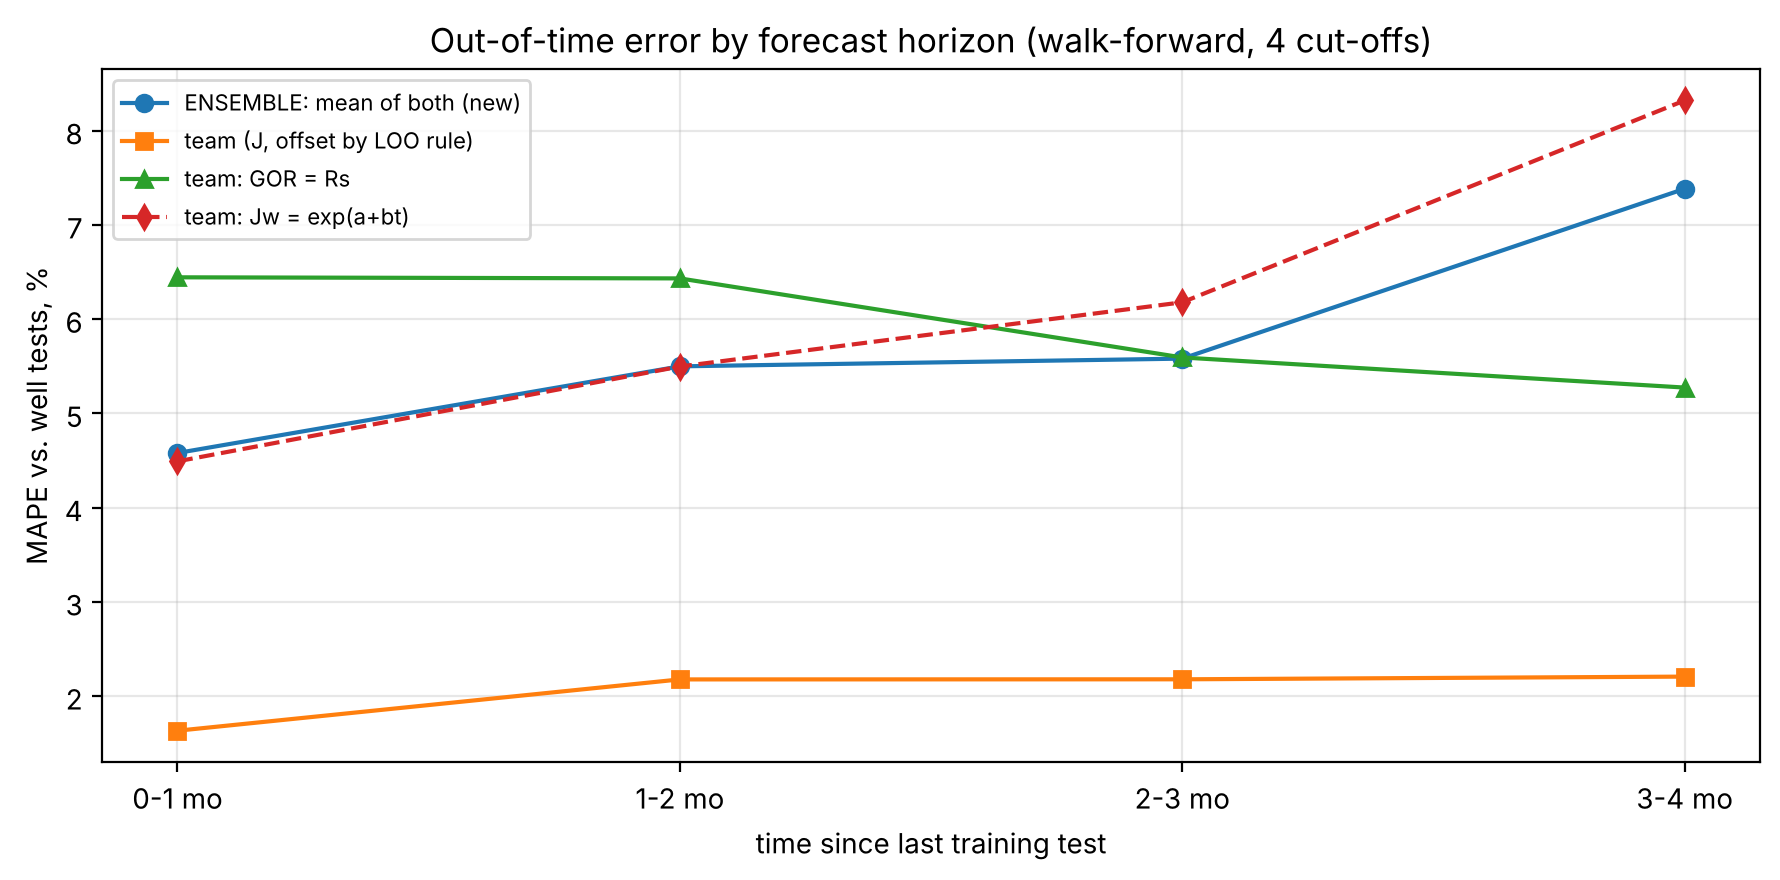

In [5]:
loo = pd.read_pickle(WORK_DIR + 'loo_table.pkl')
team_models = {'oil': 'team (J, offset by LOO rule)', 'water': 'team: Jw = exp(a+bt)', 'gas': 'team: GOR = Rs'}
cmp = pd.DataFrame({'LOO MAPE % (in-sample, notebook 03)': [loo.LOO_oil_MAPE.mean(), loo.LOO_water_MAPE.mean(), loo.LOO_gas_MAPE.mean()],
                    'walk-forward MAPE % (out-of-time)': [E[(E.stream == s) & (E.model == m_)].ape.mean() for s, m_ in team_models.items()]},
                   index=['oil', 'water', 'gas'])
cmp['optimism (pp)'] = cmp.iloc[:, 1] - cmp.iloc[:, 0]
display(cmp.round(2))
E['horizon'] = pd.cut(E.horizon_days, [0, 30, 60, 92, 130], labels=['0-1 mo', '1-2 mo', '2-3 mo', '3-4 mo'])
sel = E[E.model.isin(list(team_models.values()) + ['ENSEMBLE: mean of both (new)'])]
hz = sel.pivot_table(index='horizon', columns='model', values='ape', aggfunc='mean', observed=True)
display(hz.round(2))
fig, ax = plt.subplots(figsize=(9, 4.5))
for col, st in zip(hz.columns, ['-o', '-s', '-^', '--d']): ax.plot(hz.index.astype(str), hz[col], st, label=col)
ax.set_ylabel('MAPE vs. well tests, %'); ax.set_xlabel('time since last training test'); ax.grid(alpha=.3); ax.legend(fontsize=8)
ax.set_title('Out-of-time error by forecast horizon (walk-forward, 4 cut-offs)'); fig.tight_layout()
fig.savefig(OUT_DIR + 'walkforward_horizon.png', dpi=100); plt.show()
tab.round(3).to_csv(OUT_DIR + 'walkforward_summary.csv'); cmp.round(3).to_csv(WORK_DIR + 'loo_vs_walkforward.csv')

### Reading the results
* **Oil** (≈2% out-of-time vs ≈2% LOO) and **gas** (≈6% vs ≈5.5%): essentially no optimism → **no overfitting**. A constant productivity index per well is the right complexity; adding a time trend in J (`J linear in time`) is a textbook overfit and is clearly worse.
* **Water** is the only stream with a real gap (≈4% LOO → ≈6% out-of-time) and its error grows with horizon. That is extrapolation of the rising water-cut trend, not a bug. Averaging two different trend shapes (exponential J_w and linear WOR) reduces the variance of that extrapolation and wins at every cut-off → available as `WATER_MODEL='ensemble'` in notebook 03 (default stays `'team'` = your best-scoring submission).
* The offset rule is not stable on short histories (it switches GL-02 on at the July/August cut-offs) but on the full 9 months it only fires for GL-06, which is physically justified (≈0.35 °F error in the PVT reservoir temperature shifts the JT-implied drawdown by a constant ≈69 psi).
* **For the final submission, refit on all 9 months** (notebook 03 does this). The 6/3 split is for *choosing the model*, not for training the final model.